# WDF end to end: the paper path and the track path

WDF runs in four stages:

1. each detector's single-window triggers (the competition between the bases
   of `Bases`, statistic `EnWDF`);
2. a reconstruction of each detector's events (`Reconstruction`);
3. the graph between detectors (`Coincidence`);
4. the ranking of its candidate pairs (`Scorer`).

Stage 1 is run by a worker: `wdfUnitOnline` (causal, or zero phase at a fixed
latency) or `wdfUnitOffline`. Stages 2 to 4 are run by
`wdf.analysis.network_driver.run_network`, on one of two paths that the
configuration selects:

- **"wavegram"**, the paper path and the default: the detector graph, the
  event wavegrams and `WavegramCoincidenceFinder`;
- **"track"**: each trigger seeds a track through the detector's full ridge
  map, the waveform along the track is reconstructed, and
  `TrackCoincidenceFinder` compares the detectors' tracks and waveforms.

This tutorial runs both paths from the shipped configuration files, online
(zero phase) and offline, on two detectors. The data are synthetic and are
built in the first cell: Gaussian noise in H1 and L1, with the same chirp in
both, 7 ms later in L1. They are written to frame files, which the offline
worker reads, and they are served block by block to the online worker by an
`ArraySource`. A stretch of GWOSC data is read in the same way: give the
frame file and the channel (`FrameSource` online, `file` and `channel`
offline). Each detector's run takes a few seconds.

In [1]:
import glob
import logging
import os
import tempfile
import warnings

warnings.filterwarnings("ignore", message="h5py is running against")
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
logging.getLogger().setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from wdf.config.Parameters import load_config
from wdf.processes.wdfUnitOnline import ArraySource, wdfUnitOnline

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.15,
                     "axes.spines.top": False, "axes.spines.right": False})
INK = "#22201d"
COLOR = {"H1": "#276fbf", "L1": "#e07b39"}

import wdf

# The shipped configuration files, beside the package.
CONFIGS = os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(wdf.__file__))), "configs")
FS, GPS0, SECONDS = 4096, 1_000_000_000.0, 200.0
CHIRP_AT, CHIRP_S = 110.0, 3.0
DELAY = {"H1": 0.0, "L1": 0.007}
SEGMENT = (GPS0 + 40.0, GPS0 + SECONDS)
OUT = tempfile.mkdtemp(prefix="wdf_tutorial_")


def strain(ifo):
    # Gaussian noise with a slow drift, and a chirp from 40 to 200 Hz.
    rng = np.random.default_rng({"H1": 1, "L1": 2}[ifo])
    n = int(SECONDS * FS)
    x = 0.01 * np.cumsum(rng.standard_normal(n)) + rng.standard_normal(n)
    t = np.arange(n) / FS - CHIRP_AT - DELAY[ifo]
    inside = (t >= 0) & (t < CHIRP_S)
    f = 40.0 + 160.0 * np.clip(t, 0, CHIRP_S) / CHIRP_S
    chirp = np.where(inside, np.sin(2 * np.pi * np.cumsum(f) / FS)
                     * np.sin(np.pi * np.clip(t, 0, CHIRP_S) / CHIRP_S) ** 2, 0.0)
    return x + 0.6 * chirp


STRAIN = {ifo: strain(ifo) for ifo in DELAY}
print({ifo: x.size / FS for ifo, x in STRAIN.items()}, "s at", FS, "Hz; output in", OUT)

{'H1': 200.0, 'L1': 200.0} s at 4096 Hz; output in /tmp/wdf_tutorial_14hj3nch


## 1. The configuration

Every choice of a run is a parameter of its configuration file, and every
value used is written to the run's `parametersUsed` file.
`load_config(path, ifo, **overrides)` reads a file, applies the
`[detectors.<IFO>]` table of the detector, then the keyword arguments.

The shipped files are written for hours of GWOSC data at 4096 Hz: a 300 s fit
stretch and an autoregressive order of 3000. The overrides below shorten them
for a 200 s stretch: the fit stretch (`learn`), the model order (`ARorder`,
`ARWarmup`), the whitening's truncation (`ZeroPhaseDuration`), and the ridge's
background (`RidgeBackground`, `RidgeBackgroundMinimum`). Nothing else changes.

In [2]:
SHORT = dict(sampling=FS, learn=30, ARorder=200, ARWarmup=200, ZeroPhaseDuration=8.0,
             ARRefitInterval=0.0, RidgeBackground=32.0, RidgeBackgroundMinimum=16.0,
             outdir=OUT + "/")


def online(name, ifo, **kw):
    return load_config(os.path.join(CONFIGS, name), ifo, channel=f"{ifo}:SYNTH",
                       **SHORT, **kw)


par = online("online_zerophase_default.toml", "H1")
print("Reconstruction:", par.Reconstruction, "| Coincidence:", par.Coincidence,
      "| Scorer:", par.Scorer)
print("Bases:", par.Bases)

Reconstruction: wavegram | Coincidence: wavegram | Scorer: classic
Bases: ['Haar', 'DaubC4', 'DaubC8', 'Sym4', 'DaubC16', 'Sym8', 'Coif3', 'DaubC24', 'Sym12', 'Coif5']


## 2. Stage 1 online, zero phase: the triggers

`wdfUnitOnline` with `WhiteningMode = "zerophase"` whitens with the offline
`TruncatedWhitening`, built on a model fitted on the past only, and reads
ahead by a fixed latency, declared when the worker is built:
`Latency_s = BandPassLookahead_s + WhiteningLookahead_s`.

`segmentProcess(segment, source)` writes the triggers (Parquet), each with its
emission time, latency and label (`TriggerLatency`), the ridge candidates and
the parameters used. A trigger is labelled "glitch" when its window meets a
transient of the causal census of the whitened stream (`GlitchLabel`); the
label removes nothing.

In [3]:
from wdf.analysis.io import triggers_from_files


def run_online(name, **kw):
    out = {}
    for ifo in DELAY:
        worker = wdfUnitOnline(online(name, ifo, **kw))
        result = worker.segmentProcess(SEGMENT, ArraySource(STRAIN[ifo], GPS0, FS))
        triggers = triggers_from_files(sorted(glob.glob(worker.dir + "WDFTriggers-*.parquet")), ifo)
        out[ifo] = dict(worker=worker, result=result, triggers=triggers)
    return out


PAPER = run_online("online_zerophase_default.toml")
used = PAPER["H1"]["worker"].par
print(f"declared latency Latency_s = {used.Latency_s:g} s "
      f"(band-pass {used.BandPassLookahead_s:g} s + whitening {used.WhiteningLookahead_s:g} s)")
pd.DataFrame([dict(ifo=ifo, triggers=len(r["triggers"]),
                   glitch_labels=sum(t["label"] == "glitch" for t in r["result"].triggers),
                   latency_min=min(t["latency"] for t in r["result"].triggers),
                   latency_max=max(t["latency"] for t in r["result"].triggers))
              for ifo, r in PAPER.items()])

declared latency Latency_s = 6 s (band-pass 2 s + whitening 4 s)


,ifo,triggers,glitch_labels,latency_min,latency_max
0,H1,22,0,6.125,7.0
1,L1,24,0,6.125,7.0


## 3. Stages 2 to 4 on the paper path

`run_network(par, triggers=...)` takes each detector's triggers with their
coefficients, as `triggers_from_files` reads them, and runs with the
configuration's path:

- stage 2: `build_detector_graph`, `detector_events`, `event_coefficients`, and
  the comparison map at `NetworkComparisonBin` times the longest light travel
  time;
- stage 3: `WavegramCoincidenceFinder` over the pairs that
  `IndexedCoincidenceFinder` admits;
- stage 4: "classic" ranks each detector pair's candidates by
  `NetworkRankColumn`; "gnn" scores them with the model `GNNModel` names.

`rank` is 1 for the loudest candidate of a detector pair. With `NetworkSlides`
above zero the time-slide background is drawn and each candidate gets its
false-alarm rate (`far_hz`).

In [4]:
from wdf.analysis.network_driver import run_network

paper = run_network(par, triggers={ifo: r["triggers"] for ifo, r in PAPER.items()})
print({ifo: len(ev) for ifo, ev in paper.events.items()}, "detector events")
COLUMNS = ["rank", "gps_candidate", "ifos_involved", "network_enwdf", "dt_s",
           "network_wavegram_match", "network_wavegram_match_dt"]
top = paper.candidates.sort_values("rank")[COLUMNS].head(5).copy()
top["gps_candidate"] -= GPS0
top

{'H1': 17, 'L1': 17} detector events


,rank,gps_candidate,ifos_involved,network_enwdf,dt_s,network_wavegram_match,network_wavegram_match_dt
0,1,111.132812,"H1,L1",23.887730,-0.335938,0.625253,0.007812
1,2,111.631836,"H1,L1",18.867269,-1.333984,0.000000,NaN


## 4. Stage 1 on the track path

`configs/online_zerophase_track.toml` is the zero-phase configuration with
`Reconstruction` and `Coincidence` set to "track", and the ridge map
(`RidgeBasis`) and the track waveform (`TrackBasis`) in `LocalCos64`. The
worker needs `Ridge = true`. It keeps each trigger with its coefficients as a
seed (`TrackObserver`). Once the map is complete `TrackHorizon` seconds after
the seed's window, the worker builds the seed's track through the map, from
`TrackLookback` seconds before the window to `TrackHorizon` after it. It
reconstructs the waveform along the track and writes both (`TrackEvents`,
`TrackWaveforms`).

A track is built later than a trigger. Its declared latency adds the horizon
and the map's completion (one slot, and the part of the last map window past
it) to the stream's:

```
TrackLatency_s = Latency_s + TrackHorizon + RidgeSlot + (RidgeWindow - RidgeOverlap / 2) / rate
```

In [5]:
TRACK = run_online("online_zerophase_track.toml")
tpar = TRACK["H1"]["worker"].par
print(f"TrackLatency_s = {tpar.TrackLatency_s:g} s = {tpar.Latency_s:g} + {tpar.TrackHorizon:g} "
      f"+ {tpar.TrackCompletion_s:g} s; TrackBasis {tpar.TrackBasis}, RidgeBasis {tpar.RidgeBasis}")
rows = []
for ifo, r in TRACK.items():
    for t in r["result"].tracks:
        rows.append(dict(ifo=ifo, cluster_id=t["cluster_id"], t_start=t["track_t_start"] - GPS0,
                         t_end=t["track_t_end"] - GPS0, f_min=t["freqMin"], f_max=t["freqMax"],
                         snr=t["track_snr"], seeds=t["track_n_seeds"], method=t["track_method"],
                         latency=t["latency"]))
pd.DataFrame(rows).round(3)

TrackLatency_s = 7.46875 s = 6 + 1 + 0.46875 s; TrackBasis LocalCos64, RidgeBasis LocalCos64


,ifo,cluster_id,t_start,t_end,f_min,f_max,snr,seeds,method,latency
0,H1,0,84.594,84.906,107.635,861.078,14.338,1,anchored,7.875
1,H1,1,94.375,96.469,26.909,1024.000,30.938,1,anchored,7.375
2,H1,2,110.500,112.500,26.909,1024.000,34.286,3,anchored,7.250
3,H1,3,117.531,118.062,38.055,861.078,15.207,1,ridge,7.250
4,H1,4,126.344,126.438,38.055,64.000,4.942,1,anchored,7.250
5,H1,5,140.344,140.375,724.077,861.078,5.108,1,anchored,7.375
6,H1,6,141.500,141.531,724.077,861.078,5.466,1,anchored,7.250
7,H1,7,147.406,148.906,38.055,1024.000,30.888,2,ridge,7.125
8,H1,8,150.094,152.031,26.909,1024.000,30.375,1,ridge,7.875
9,H1,9,173.094,174.781,26.909,1024.000,24.767,1,anchored,8.000


The tracks of the chirp in the two detectors, f(t) as the path's states, and
the reconstructed waveforms, in units of the noise scale:

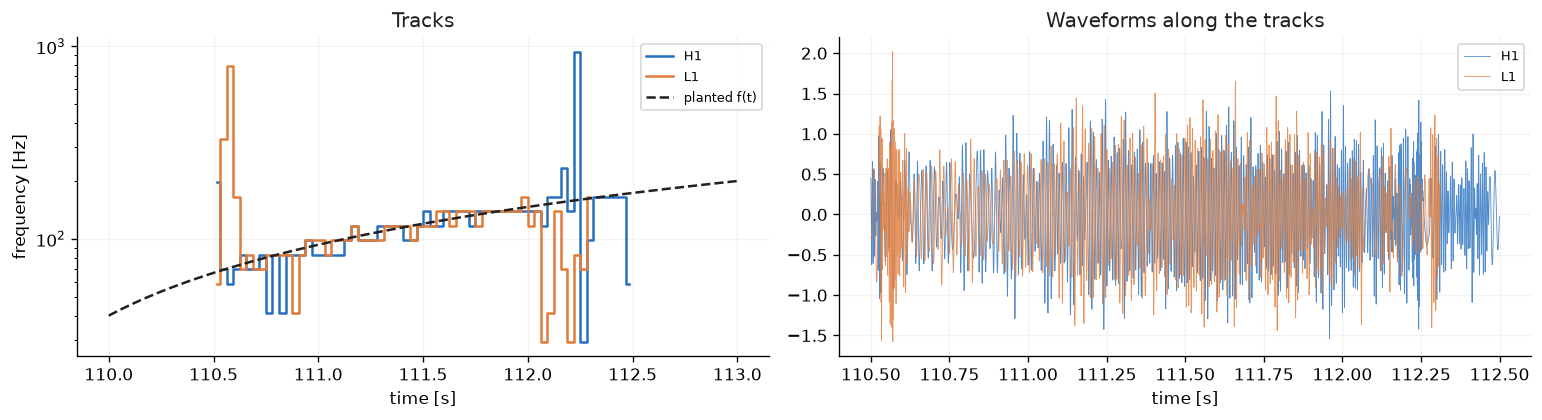

In [6]:
from wdf.analysis.track_reconstruction import load_tracks

TRACKS, WAVEFORMS = {}, {}
for ifo, r in TRACK.items():
    folder = r["worker"].dir
    TRACKS[ifo], WAVEFORMS[ifo] = load_tracks(glob.glob(folder + "TrackEvents-*.csv")[0],
                                              glob.glob(folder + "TrackWaveforms-*.npz")[0])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ifo, ev in TRACKS.items():
    on = ev[(ev["track_t_end"] > GPS0 + CHIRP_AT) & (ev["track_t_start"] < GPS0 + CHIRP_AT + CHIRP_S)]
    for _, row in on.iterrows():
        axes[0].step(np.asarray(row["track_times"]) - GPS0, row["track_f"], where="mid",
                     color=COLOR[ifo], label=ifo)
        t0, y = WAVEFORMS[ifo][int(row["cluster_id"])]
        axes[1].plot(t0 - GPS0 + np.arange(y.size) / used.resampling, y, lw=0.5,
                     color=COLOR[ifo], label=ifo, alpha=0.8)
t = np.linspace(CHIRP_AT, CHIRP_AT + CHIRP_S, 50)
axes[0].plot(t, 40 + 160 * (t - CHIRP_AT) / CHIRP_S, ls="--", color=INK, label="planted f(t)")
axes[0].set_yscale("log")
axes[0].set_xlabel("time [s]")
axes[0].set_ylabel("frequency [Hz]")
axes[0].set_title("Tracks", color=INK)
axes[0].legend(fontsize=8)
axes[1].set_xlabel("time [s]")
axes[1].set_title("Waveforms along the tracks", color=INK)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Stages 2 to 4 on the track path

`run_network(par, tracks=..., waveforms=...)` reads the track events and
waveforms. `TrackCoincidenceFinder` keeps the pairs `IndexedCoincidenceFinder`
admits and adds the track features:

- `track_time_overlap`, `track_f_distance`, `track_f_overlap` and
  `track_compatible` compare the two tracks' spans and f(t), within the light
  travel time plus `TrackTimingJitter`, with tolerance
  `TrackFrequencyTolerance` octaves;
- `track_lag_s`, `track_coherence` and `track_phase` come from the complex
  cross-correlation of the two waveforms' analytic signals over the lags the
  light travel time allows: the lag of its largest modulus, that modulus
  (from 0 to 1) and its phase.

`track_lag_s` follows the convention of `dt_s` (H1 time minus L1 time); the
chirp was planted 7 ms later in L1.

In [7]:
track = run_network(tpar, tracks=TRACKS, waveforms=WAVEFORMS)
COLUMNS = ["rank", "gps_candidate", "ifos_involved", "network_enwdf", "dt_s", "track_lag_s",
           "track_coherence", "track_phase", "track_compatible", "track_f_distance"]
top = track.candidates.sort_values("rank")[COLUMNS].head(5).copy()
top["gps_candidate"] -= GPS0
top.round(4)

,rank,gps_candidate,ifos_involved,network_enwdf,dt_s,track_lag_s,track_coherence,track_phase,track_compatible,track_f_distance
0,1,111.4055,"H1,L1",23.8877,1.6724,-0.0068,0.6134,-1.6129,1.0,0.1419
1,2,189.2188,"H1,L1",8.0496,-0.8828,-0.0075,0.0197,1.7817,0.0,1.0676


## 6. The basis of the track's waveform

`TrackBasis` chooses the basis in which the coefficients under the track are
kept and inverted:

- `LocalCos64`: 31.25 ms by 16 Hz tiles at 2048 Hz;
- `LocalCos128`: 62.5 ms by 8 Hz tiles;
- `CosinePackets<m>`: the cosine-packet best basis of the whitened stream over
  the track's span, with segments from `m` samples (`TrackPacketCost`).

When `TrackBasis` is the map's `RidgeBasis`, the waveform reads the map's own
coefficients. Otherwise it is recomputed on the whitened stream held by the
map. Below, H1 is run three times, once with each basis. The table gives the
normalised overlap of each chirp waveform with the planted chirp. The noise is
white across the chirp's band, so there the whitening only scales the chirp,
which a normalised overlap ignores.

In [8]:
BASES = ["LocalCos64", "LocalCos128", "CosinePackets32"]
rows, curves = [], {}
for basis in BASES:
    worker = wdfUnitOnline(online("online_zerophase_track.toml", "H1", TrackBasis=basis,
                                  SearchName=f"track_{basis}"))
    result = worker.process(ArraySource(STRAIN["H1"], GPS0, FS), *SEGMENT)
    on = [r for r in result.tracks
          if r["track_t_end"] > GPS0 + CHIRP_AT and r["track_t_start"] < GPS0 + CHIRP_AT + CHIRP_S]
    best = max(on, key=lambda r: r["track_snr"])
    t0, y = result.track_waveforms[best["cluster_id"]]
    curves[basis] = (t0, y)
    rows.append(dict(TrackBasis=basis, t_start=best["track_t_start"] - GPS0,
                     t_end=best["track_t_end"] - GPS0, energy=best["track_energy"]))

def planted(t):
    # The chirp as planted in H1, at the given GPS times.
    u = t - GPS0 - CHIRP_AT - DELAY["H1"]
    inside = (u >= 0) & (u < CHIRP_S)
    phase = 2 * np.pi * (40.0 * u + 80.0 * u ** 2 / CHIRP_S)
    return np.where(inside, np.sin(phase) * np.sin(np.pi * np.clip(u, 0, CHIRP_S) / CHIRP_S) ** 2, 0.0)


for row in rows:
    t0, y = curves[row["TrackBasis"]]
    c = planted(t0 + np.arange(y.size) / used.resampling)
    row["overlap"] = float(np.dot(y, c) / np.sqrt(np.sum(y ** 2) * np.sum(c ** 2)))
pd.DataFrame(rows).round(3)

,TrackBasis,t_start,t_end,energy,overlap
0,LocalCos64,110.5,112.5,1175.540,0.785
1,LocalCos128,110.5,112.5,1335.684,0.806
2,CosinePackets32,110.5,112.5,2158.356,0.781


## 7. The offline flow

`wdfUnitOffline` reads frame files. Its configuration, `offline_default.toml`,
includes M4 glitch subtraction, whose coincidence protection needs every
detector's census. `offline_network` therefore runs the census of all the
detectors first, then each detector's segment, so that a transient coincident
in the detectors (here, the chirp) is protected and kept. Each run records
`GlitchProtection` ("on", with the protecting detectors in
`GlitchProtectionDetectors`). A detector run alone records it as "OFF (single
detector ...)". It also records the span searched (`gpsEndSearched`,
`UnsearchedTail_s`).

Setting `Reconstruction = "track"` and `Coincidence = "track"` makes the
offline worker build the tracks after the segment's ridge, on its map and its
whitened stream. Its frame files are written here from the same strain.

In [9]:
from gwpy.timeseries import TimeSeries

from wdf.processes.wdfUnitOffline import offline_network

FRAMES = {}
for ifo, x in STRAIN.items():
    FRAMES[ifo] = os.path.join(OUT, f"{ifo}-SYNTH.gwf")
    TimeSeries(x, t0=GPS0, sample_rate=FS, name=f"{ifo}:SYNTH",
               channel=f"{ifo}:SYNTH").write(FRAMES[ifo])

OFFLINE = dict(sampling=FS, learn=30, ARorder=200, AREstimationOffset=5.0, len=8.0,
               ZeroPhaseDuration=8.0, RidgeBackground=32.0, RidgeBackgroundMinimum=16.0,
               outdir=OUT + "/offline/", Reconstruction="track", Coincidence="track")
pars = {ifo: load_config(os.path.join(CONFIGS, "offline_default.toml"), ifo,
                         channel=f"{ifo}:SYNTH", file=FRAMES[ifo], **OFFLINE) for ifo in DELAY}
done = offline_network(pars, (GPS0, GPS0 + SECONDS))
pd.DataFrame([dict(ifo=ifo, protection=w.par.GlitchProtection,
                   protected_by=w.par.GlitchProtectionDetectors,
                   seeds=w.par.GlitchSeeds, protected=w.par.GlitchSeedsProtected,
                   atoms=w.par.GlitchAtoms, tracks=w.par.TrackCount,
                   searched_to=w.par.gpsEndSearched - GPS0,
                   unsearched_tail_s=w.par.UnsearchedTail_s)
              for ifo, w in done["workers"].items()])

,ifo,protection,protected_by,seeds,protected,atoms,tracks,searched_to,unsearched_tail_s
0,H1,on,[L1],0,0,0,17,132.0,68.0
1,L1,on,[H1],0,0,0,12,132.0,68.0


In [10]:
offline = run_network(pars["H1"], tracks={i: w.track_events for i, w in done["workers"].items()},
                      waveforms={i: w.track_waveforms for i, w in done["workers"].items()})
top = offline.candidates.sort_values("rank")[COLUMNS].head(5).copy()
top["gps_candidate"] -= GPS0
top.round(4)

,rank,gps_candidate,ifos_involved,network_enwdf,dt_s,track_lag_s,track_coherence,track_phase,track_compatible,track_f_distance
0,1,112.165,"H1,L1",23.6305,-0.4023,-0.0068,0.7042,-1.5985,1.0,0.0


## 8. Choosing a path

| | paper path | track path |
|---|---|---|
| set | `Reconstruction = Coincidence = "wavegram"` (default) | `Reconstruction = Coincidence = "track"`, `Ridge = true` |
| stage 2 reads | the triggers and their coefficients | the worker's `TrackEvents` and `TrackWaveforms` |
| stage 3 | `WavegramCoincidenceFinder` | `TrackCoincidenceFinder` |
| online latency | `Latency_s` | `TrackLatency_s` (adds `TrackHorizon` and the map's completion) |
| GNN | `cross_edge_dim = N_EDGE_FEATURES` | a model fitted with `N_EDGE_FEATURES + len(TRACK_EDGE_FEATURES)` |

The two paths do not mix: `network_path` refuses a configuration with
`Reconstruction` and `Coincidence` on different paths, and `Scorer = "gnn"`
without `GNNModel`. Stage 1 is the same on both paths. On the paper path the
triggers, detector events and network table are the same as before the track
path was added.